Import necessary Libraries

In [1]:
import os
import random
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, regularizers
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.utils import image_dataset_from_directory #Allow import own dataset
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import img_to_array,array_to_img
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image,ImageEnhance,ImageDraw
from tkinter import Tk, filedialog
!pip install ipywidgets
from ipywidgets import FileUpload
from IPython.display import display
import io

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip available: 22.3 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Image Preprocessing

In [2]:
# Set path
input_dir = 'C:\\Users\\user\\Desktop\\FYPSystem\\f_y_p_skin_diagnosis_app\\assets\\dataset\\raw_images'  # your original images root folder, subfolders = labels
output_dir = 'C:\\Users\\user\\Desktop\\FYPSystem\\f_y_p_skin_diagnosis_app\\assets\\dataset\\augmented_images'  # where to save augmented images
target_size =(224,224)  # resize target

# Import necessary Libraries
import os
import random
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, regularizers
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.utils import image_dataset_from_directory #Allow import own dataset

In [3]:
# Augmentation Functions
def random_crop(img,crop_size = (180,180)):
    width,height = img.size
    max_left = width - crop_size[0]
    max_top = height - crop_size[1]
    left = random.randint(0,max_left)
    top = random.randint(0,max_top)
    right = left + crop_size[0]
    bottom = top + crop_size[1]
    cropped = img.crop((left,top,right,bottom))
    return cropped.resize(target_size)

def color_jitter(img):
  # Change brightness, contrast, saturation separately
  enhancers = [
      ImageEnhance.Brightness(img),
      ImageEnhance.Contrast(img),
      ImageEnhance.Color(img)
  ]

  for enhancer in enhancers:
    # Choose a random range for the enhancer variable
    if random.random() < 0.5:  # 50% chance for the first range
        enhance_factor = random.uniform(0.0, 0.5)
    else:  # 50% chance for the second range
        enhance_factor = random.uniform(1.5, 2.0)
    img = enhancer.enhance(enhance_factor)

  return img

def random_rotate_resize(img):
  angle = random.uniform(-50,50)
  img = img.rotate(angle,expand = True)
  # Random resize scale between 0.8 and 1.2
  scale = random.uniform(0.5,1.5)
  new_size = (int(img.width * scale),int(img.height * scale))
  img = img.resize(new_size)
  return img.resize(target_size)

def block_random_part(img):
  draw = ImageDraw.Draw(img)
  width,height = img.size
  # Draw random rectangle or ellipse with black color blocking
  shape_type = random.choice(['rectange','ellipse'])
  size_width = random.randint(width//9,width//9)
  size_height = random.randint(height//9,height//9)
  left = random.randint(0,width - size_width)
  top = random.randint(0,height - size_height)
  right = left + size_width
  bottom = top + size_height

  if shape_type == 'rectange':
    draw.rectangle([left,top,right,bottom],fill = (0,0,0))
  else:
    draw.ellipse([left,top,right,bottom],fill = (0,0,0))
  return img

In [4]:
# Save Image
def save_image(img,label,base_filename,aug_name,count):
  out_label_dir = os.path.join(output_dir,label)
  os.makedirs(out_label_dir,exist_ok = True)
  out_filename = f'{base_filename}_{aug_name}_{count}.jpg'
  out_path = os.path.join(out_label_dir,out_filename)
  img.save(out_path)

In [5]:
# Process Images
def augment_dataset():
  count = 0

  # Get all subfolders in dataset folder dynamically
  subfolders = [d for d in os.listdir(input_dir) if os.path.isdir(os.path.join(input_dir,d))]
  print(f"Found {len(subfolders)} subfolders: {subfolders}")

  for label in subfolders:
    label_path= os.path.join(input_dir,label)

    for img_file in os.listdir(label_path):
      valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tiff', '.tif', '.gif', '.webp')

      # Then in the loop:
      if not img_file.lower().endswith(valid_extensions):
        continue

      base_filename = os.path.splitext(img_file)[0]
      img_path = os.path.join(label_path,img_file)
      img = Image.open(img_path).convert('RGB').resize(target_size)

      # Save original resized image
      save_image(img,label,base_filename,'original',count)
      count += 1

      # Apply augmentations one by one
      aug_funcs = [
          ('color_jitter', color_jitter),
          ('crop', random_crop),
          ('rotate_resize', random_rotate_resize),
          ('block', block_random_part),
      ]

      for aug_name, aug_func in aug_funcs:
        try:
          aug_img = aug_func(img.copy())  # Use aug_func instead of func
          save_image(aug_img, label, base_filename, aug_name, count)
          count += 1
        except Exception as e:
          print(f"Error augmenting {img_file} with {aug_name}: {e}")


    print(f"Processed {count} images including augmentations.")

if __name__ == "__main__":
  augment_dataset()

Found 10 subfolders: ['Acne', 'Birthmark', 'Chicken Pox', 'Eczema', 'Hand Foot and Mouth', 'Measles', 'Melanoma', 'Shingles', 'Skin Tag', 'Wart']
Processed 765 images including augmentations.
Processed 1620 images including augmentations.
Processed 1865 images including augmentations.
Processed 2600 images including augmentations.
Processed 2935 images including augmentations.
Processed 3010 images including augmentations.
Processed 4335 images including augmentations.
Processed 4660 images including augmentations.
Processed 5060 images including augmentations.
Processed 5315 images including augmentations.


Load dataset and train

In [6]:
# Directory where your skin images are stored (change this path)
dataset_dir = 'C:\\Users\\user\\Desktop\\FYPSystem\\f_y_p_skin_diagnosis_app\\assets\\dataset\\augmented_images'

In [7]:
# Load the dataset with augmentation
augmentation = tf.keras.Sequential([
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

# Load the dataset using image_dataset_from_directory
# Keep the original dataset returned by image_dataset_from_directory to access class_names
original_train_ds = image_dataset_from_directory(
    dataset_dir,
    labels='inferred', # Labels are inferred from the directory structure
    label_mode='categorical', # Use categorical labels for multi-class classification
    image_size=(32, 32), # Resize images to 32x32
    interpolation='nearest',
    batch_size=16, # Set batch size
    shuffle=True, # Shuffle the data
    validation_split=0.3, # Use 30% of the data for validation
    subset='training', # Specify this is the training set
    seed=123  # Add a seed value for reproducibility
)

# Get class names from the original dataset
class_names = original_train_ds.class_names
print(f"Class names: {class_names}")

# Apply augmentation to the training dataset
train_ds = original_train_ds.map(lambda x, y: (augmentation(x), y))

# Load the combined validation and test dataset (30% of total)
combined_val_test_ds = image_dataset_from_directory(
    dataset_dir,
    labels='inferred',
    label_mode='categorical',
    image_size=(32, 32),
    interpolation='nearest',
    batch_size=16,
    shuffle=False, # No need to shuffle combined validation/test set yet
    validation_split=0.3,
    subset='validation', # Specify this is the validation/test subset
    seed = 123
)

# Apply rescaling to the combined validation/test dataset
combined_val_test_ds = combined_val_test_ds.map(lambda x, y: (tf.cast(x,tf.float32) / 255.0, y))

# Get class names - This line is not needed as class_names is already defined above.
# class_names = train_ds.class_names
print(f"Class names: {class_names}")

Found 5315 files belonging to 10 classes.
Using 3721 files for training.
Class names: ['Acne', 'Birthmark', 'Chicken Pox', 'Eczema', 'Hand Foot and Mouth', 'Measles', 'Melanoma', 'Shingles', 'Skin Tag', 'Wart']
Found 5315 files belonging to 10 classes.
Using 1594 files for validation.
Class names: ['Acne', 'Birthmark', 'Chicken Pox', 'Eczema', 'Hand Foot and Mouth', 'Measles', 'Melanoma', 'Shingles', 'Skin Tag', 'Wart']


In [8]:
# Split the combined validation/test dataset into 15% validation and 15% test

# First, determine the number of batches in the combined dataset
num_combined_batches = tf.data.experimental.cardinality(combined_val_test_ds).numpy()

# If the dataset size is unknown (-2), you might need to iterate through it to count or use a known dataset size
if num_combined_batches == -2:
    print("Warning: Dataset cardinality unknown. Cannot perform split by batch count.")
    print("You may need to adjust the splitting method or provide a known dataset size.")
    # As an alternative, you could try converting to numpy and splitting:
    # images, labels = tuple(zip(*combined_val_test_ds.unbatch().as_numpy_iterator()))
    # from sklearn.model_selection import train_test_split
    # X_val, X_test, y_val, y_test = train_test_split(images, labels, test_size=0.5, random_state=42, stratify=labels)
    # val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(32).cache().prefetch(buffer_size=tf.data.AUTOTUNE)
    # test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(32).cache().prefetch(buffer_size=tf.data.AUTOTUNE)

else:
    # We want to split the 30% combined set into two equal halves (15% each)
    # So, we take the first half of the batches for validation and the second half for testing.
    num_val_batches = num_combined_batches // 2
    num_test_batches = num_combined_batches - num_val_batches # Ensure all batches are used

    val_ds = combined_val_test_ds.take(num_val_batches)
    test_ds = combined_val_test_ds.skip(num_val_batches).take(num_test_batches)

    print(f"Number of validation batches: {tf.data.experimental.cardinality(val_ds).numpy()}")
    print(f"Number of test batches: {tf.data.experimental.cardinality(test_ds).numpy()}")

    # Note: This splits by batches, not necessarily exact image counts if batch size varies or is not divisible.
    # For exact splits, converting to numpy arrays and using train_test_split is more precise,
    # but this method works well with tf.data.Dataset and is closer to your original logic.


Number of validation batches: 50
Number of test batches: 50


Show the images

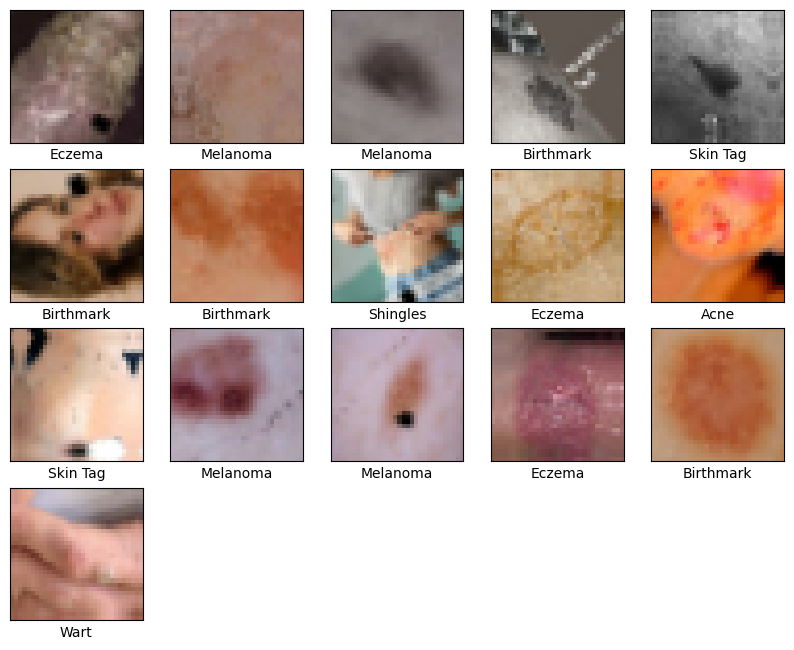

In [9]:
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i].numpy())
        plt.xlabel(class_names[np.argmax(labels[i])])
    plt.show()

Build and the model

In [10]:
# Define the model with regularization
num_classes = len(class_names) # Define num_classes

# Define the model with increased regularization and better architecture
model = models.Sequential([
    # First convolutional block
    layers.Conv2D(128, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),  # Dropout after first Conv2D layer

    # Second convolutional block
    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),  # Dropout after second Conv2D layer

    # Third convolutional block
    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),  # Dropout after third Conv2D layer

    # Flatten layer to transition from convolutional to dense layers
    layers.Flatten(),

    # Additional Dropout and BatchNormalization before dense layers
    layers.Dropout(0.5),  # Dropout before dense layers
    layers.BatchNormalization(),  # Added BatchNormalization for better convergence

    # First Dense Layer with L2 regularization
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),

    # Second Dense Layer with higher dropout
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),  # Optional regularization for added regularity

    # Output layer with softmax activation for classification
    layers.Dense(num_classes, activation='softmax')
])

C:\Users\user\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 128)    │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,973,706 (7.53 MB)

 Trainable params: 1,964,234 (7.49 MB)

 Non-trainable params: 9,472 (37.00 KB)

Compile and Train the Model

In [12]:
# Compile the model
model.compile(optimizer = 'adam',
              loss = tf.keras.losses.CategoricalCrossentropy(),
              metrics = ['accuracy'])

# Set callbacks for early stopping and model checkpointing
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.h5', save_best_only=True)

# Train the model with callbacks
history = model.fit(train_ds, epochs = 120,
                    validation_data = val_ds)

Epoch 1/120


233/233 ━━━━━━━━━━━━━━━━━━━━ 70s 282ms/step - accuracy: 0.2895 - loss: 2.8265 - val_accuracy: 0.5188 - val_loss: 2.2576
Epoch 2/120
233/233 ━━━━━━━━━━━━━━━━━━━━ 56s 168ms/step - accuracy: 0.3510 - loss: 2.5072 - val_accuracy: 0.4900 - val_loss: 2.2150
Epoch 3/120
233/233 ━━━━━━━━━━━━━━━━━━━━ 41s 175ms/step - accuracy: 0.3706 - loss: 2.4430 - val_accuracy: 0.4812 - val_loss: 2.0882
Epoch 4/120
233/233 ━━━━━━━━━━━━━━━━━━━━ 29s 120ms/step - accuracy: 0.3962 - loss: 2.3588 - val_accuracy: 0.6525 - val_loss: 1.7378
Epoch 5/120
233/233 ━━━━━━━━━━━━━━━━━━━━ 30s 128ms/step - accuracy: 0.4183 - loss: 2.2388 - val_accuracy: 0.6212 - val_loss: 1.7566
Epoch 6/120
233/233 ━━━━━━━━━━━━━━━━━━━━ 28s 121ms/step - accuracy: 0.4337 - loss: 2.1755 - val_accuracy: 0.6438 - val_loss: 1.5541
Epoch 7/120
233/233 ━━━━━━━━━━━━━━━━━━━━ 34s 146ms/step - accuracy: 0.4371 - loss: 2.0902 - val_accuracy: 0.6600 - val_loss: 1.5566
Epoch 8/120
233/233 ━━━━━━━━━━━━━━━━━━━━ 32s 136ms/step - accuracy: 0.4422 - loss: 2.032

Save the trained model

In [13]:
# Save the model in the native Keras format
model.save('skin_lesion_model.keras')
print("Model saved in Keras format.")

Model saved in Keras format.


In [14]:
# Load the Keras model
model = tf.keras.models.load_model('skin_lesion_model.keras')

# Convert the model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the TFLite model to a file
with open('skin_lesion_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("Model converted to TFLite and saved as 'skin_lesion_model.tflite'")

INFO:tensorflow:Assets written to: C:\Users\user\AppData\Local\Temp\tmpiwa1t466\assets


INFO:tensorflow:Assets written to: C:\Users\user\AppData\Local\Temp\tmpiwa1t466\assets


Saved artifact at 'C:\Users\user\AppData\Local\Temp\tmpiwa1t466'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  2613431994128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613431993168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613432389264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613432391568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613432002960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613432398288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613432389072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613432396752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613432387536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2613432397136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  261343

Evaluation

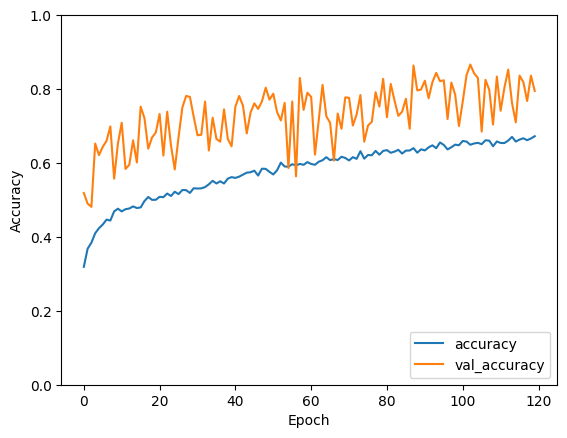

In [15]:
# Extract images and labels from test_ds for evaluation
test_images = []
test_labels = []
for images, labels in val_ds.take(1):  # Take one batch for testing
    test_images.extend(images.numpy())
    test_labels.extend(labels.numpy())

# Convert lists to NumPy arrays
test_images = np.array(test_images)
test_labels = np.array(test_labels)

plt.plot(history.history['accuracy'],label = 'accuracy')
plt.plot(history.history['val_accuracy'],label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0,1])
plt.legend(loc = 'lower right')
plt.show()

In [16]:
# Evaluate
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"Test Accuracy: {test_acc:.2f}")

1/1 - 1s - 992ms/step - accuracy: 0.8125 - loss: 0.9380
Test Accuracy: 0.81


Execution

In [51]:
#Load the trained model (if not already in memory)
model = tf.keras.models.load_model('skin_lesion_model.tflite')

#Define class names manually or load from dataset
class_names = original_train_ds.class_names

ValueError: File format not supported: filepath=skin_lesion_model.tflite. Keras 3 only supports V3 `.keras` files and legacy H5 format files (`.h5` extension). Note that the legacy SavedModel format is not supported by `load_model()` in Keras 3. In order to reload a TensorFlow SavedModel as an inference-only layer in Keras 3, use `keras.layers.TFSMLayer(skin_lesion_model.tflite, call_endpoint='serving_default')` (note that your `call_endpoint` might have a different name).

In [53]:
# --- Open File Dialog ---

# Create a FileUpload widget
uploader = FileUpload(
    accept='.png,.jpg,.jpeg,.jfif',  # Accepted file extensions
    multiple=False  # Allow only one file selection
)

print("Please upload an image:")
display(uploader)

Please upload an image:


FileUpload(value=(), accept='.png,.jpg,.jpeg,.jfif', description='Upload')

Processing file: warttest.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
-----
Prediction: Wart - Confidence: 0.96


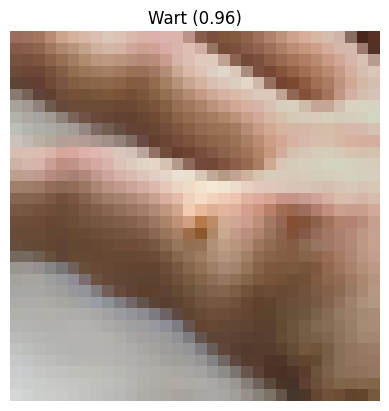

In [87]:
if uploader.value:
    # Get the uploaded file information (uploader.value is a tuple)
    # The structure is: uploader.value = (file_info_dict,)
    uploaded_file_info = uploader.value[0]
    file_content = uploaded_file_info['content']
    
    # Try to get the filename - different structures possible
    try:
        file_name = uploaded_file_info['metadata']['name']
    except KeyError:
        # Alternative structure - filename might be directly in the dict
        file_name = uploaded_file_info.get('name', 'uploaded_image')
    
    print(f"Processing file: {file_name}")

    # Convert the bytes content to a PIL Image
    img = Image.open(io.BytesIO(file_content))

    # Resize the image to match your model's input size
    img = img.resize((32, 32))

    # Load and preprocess the selected image (from the uploaded file content)
    image_array = image.img_to_array(img)
    image_array = np.expand_dims(image_array, axis=0)
    image_array /= 255.0

    # Make prediction
    predictions = model.predict(image_array)
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0])

    # Display result
    print("-----")
    print(f"Prediction: {class_names[predicted_class]} - Confidence: {confidence:.2f}")

    # Show image
    plt.imshow(img)
    plt.title(f"{class_names[predicted_class]} ({confidence:.2f})")
    plt.axis('off')
    plt.show()
else:
    print("No file selected.")